# Programas de sanciones OFAC: composición del listado

## Resumen
El corte descargado contiene 19.564 designaciones y 247 valores distintos del campo de programas, incluidas combinaciones.

Una mesa de cumplimiento necesita dimensionar la diversidad de programas en un listado público. Se cuentan designaciones, no alertas ni delitos.

**Alcance:** El programa es una etiqueta de sanción, no una tipología de lavado. Una persona puede tener alias o identificadores múltiples; el conteo no representa casos ni probabilidad de delito. La lista de Estados Unidos no determina obligaciones de una entidad colombiana.

**Hallazgo del corte:** La etiqueta más frecuente del corte tiene 5.664 filas; las etiquetas pueden combinar programas y no deben sumarse como personas únicas.

## Contexto y método
Aplicación descriptiva reproducible. Las cantidades son agregadas a partir del archivo citado; no se infiere causalidad ni desempeño institucional.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').exists())
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Datos
Corte de [OFAC SDN, formatos y esquema](https://ofac.treasury.gov/specially-designated-nationals-list-data-formats-data-schemas), descargado el 12 de noviembre de 2026. La unidad es una fila de designación en el archivo SDN; el campo de programa puede combinar varios programas. La fuente y sus actualizaciones deben verificarse antes de cualquier uso operativo. Python con pandas, matplotlib y Jupyter; ejecutar desde la raíz o una subcarpeta del repositorio.

In [2]:
source = '03-financial-risk/05-enterprise-risk-advisory/05-financial-crime/aml-typologies/data/ofac_sdn_2026-11-12.csv'
p = root / source
print('Archivo:', source, '\nSHA-256:', hashlib.sha256(p.read_bytes()).hexdigest())
assert hashlib.sha256(p.read_bytes()).hexdigest() == '7f43332dae0d1b78ce44c31692d87a3c66e4075bcd97e36d3f18585572ff55b8', 'La instantánea cambió: revisar fecha, esquema y actualizar hash documentado'

Archivo: 03-financial-risk/05-enterprise-risk-advisory/05-financial-crime/aml-typologies/data/ofac_sdn_2026-11-12.csv 
SHA-256: 7f43332dae0d1b78ce44c31692d87a3c66e4075bcd97e36d3f18585572ff55b8


## Resultados

Designaciones: 19564 | etiquetas distintas del campo programas: 247


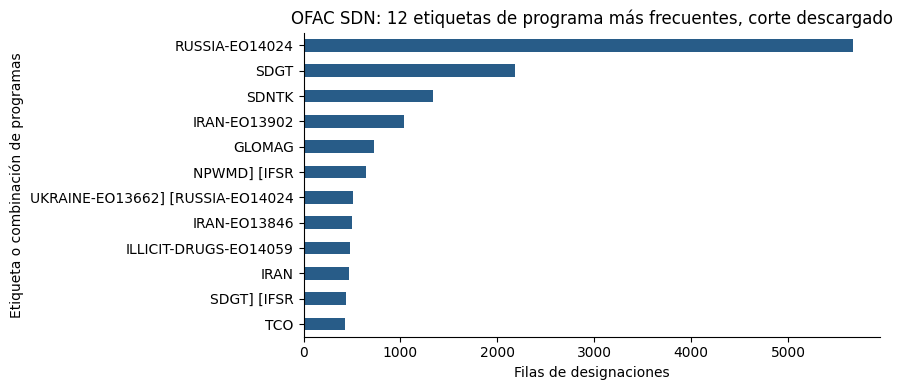

,designaciones
3,
RUSSIA-EO14024,5664
SDGT,2185
SDNTK,1332
IRAN-EO13902,1040
GLOMAG,723
NPWMD] [IFSR,644
UKRAINE-EO13662] [RUSSIA-EO14024,507
IRAN-EO13846,502
ILLICIT-DRUGS-EO14059,475


In [3]:
raw = pd.read_csv(root / source, header=None, dtype=str, keep_default_na=False)
assert raw.shape[1] == 12 and len(raw) > 0 and raw[0].str.strip().ne('').all() and raw[0].is_unique
programs = raw[3].str.strip().replace('-0-', 'SIN PROGRAMA').value_counts()
print('Designaciones:', len(raw), '| etiquetas distintas del campo programas:', len(programs))
programs.head(12).sort_values().plot.barh(color='#285c88', xlabel='Filas de designaciones', title='OFAC SDN: 12 etiquetas de programa más frecuentes, corte descargado')
plt.ylabel('Etiqueta o combinación de programas'); plt.tight_layout(); plt.show()
programs.head(12).to_frame('designaciones')

## Variante: etiquetas individuales y solapamiento

La descripción por combinación de programas se complementa con una tabla de pertenencia a etiquetas individuales, dividiendo el campo por el separador `] [`. Una designación puede pertenecer a varios programas; por tanto, las participaciones por programa se solapan y no deben sumarse. Se trata de composición descriptiva del corte, no de probabilidades de lavado o de coincidencia de un cliente. La [especificación de formatos de OFAC](https://ofac.treasury.gov/faqs/topic/1641) distingue los formatos de publicación, mientras su [marco de cumplimiento](https://ofac.treasury.gov/system/files/126/framework_ofac_cc.pdf) sitúa el listado dentro de una evaluación de riesgos y controles más amplia.

In [4]:
import re
entries = raw[[0,3]].copy()
entries.columns = ['id_designacion','programas']
entries['etiquetas'] = entries.programas.map(lambda x: [] if x.strip() in ('','-0-') else [z.strip(' []') for z in re.split(r'\]\s*\[', x.strip()) if z.strip(' []')])
entries['numero_etiquetas'] = entries.etiquetas.map(len)
print('Designaciones con varias etiquetas:', int((entries.numero_etiquetas > 1).sum()), 'de', len(entries))
print('Designaciones sin etiqueta:', int(entries.numero_etiquetas.eq(0).sum()))
memberships = entries[['id_designacion','etiquetas']].explode('etiquetas').dropna().drop_duplicates()
assert not memberships.duplicated(['id_designacion','etiquetas']).any()
by_label = memberships.groupby('etiquetas').id_designacion.nunique().sort_values(ascending=False).to_frame('designaciones')
by_label['porcentaje_del_corte'] = 100 * by_label.designaciones / len(entries)
by_label.head(12).round(2)

Designaciones con varias etiquetas: 3034 de 19564
Designaciones sin etiqueta: 1


,designaciones,porcentaje_del_corte
etiquetas,,
RUSSIA-EO14024,6346,32.44
SDGT,3360,17.17
IFSR,1620,8.28
SDNTK,1363,6.97
NPWMD,1205,6.16
IRAN-EO13902,1100,5.62
ILLICIT-DRUGS-EO14059,787,4.02
GLOMAG,739,3.78
IRAN,679,3.47


## Interpretación y límites
Cada valor del campo puede combinar varios programas. El programa es una etiqueta de sanción, no una tipología de lavado. Una persona puede tener alias o identificadores múltiples; el conteo no representa casos ni probabilidad de delito. La lista de Estados Unidos no determina obligaciones de una entidad colombiana.

La cifra y la gráfica son descriptivas del corte disponible; las decisiones requieren datos propios, revisión de calidad y validación independiente.

**Acción siguiente:** contrastar con datos autorizados de la entidad, definir población y umbrales antes de cualquier decisión, y conservar la fecha y el hash del corte usado. Los controles de este notebook son de calidad local y no sustituyen revisión independiente.